# Lab 3: Supervised learning II (model families)

Neighbours, naive Bayes, trees, ensembles and support vector machines, compared under the
fixed validation workflow from Lab 2: inspect boundaries, tree depth, ensemble gains and SVM
tuning.

This notebook follows the Lab 3 handout: Parts A to D, then the *Try it yourself* tasks, the
verification checklist and the *Check your understanding* questions. The code saves every
chart and table to `results/lab03/` and the tuned SVM to `models/`.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Notebooks live in all_experiments/, so the course folder is one level up.
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)
RESULTS = PROJECT_ROOT / "results" / "lab03"
RESULTS.mkdir(parents=True, exist_ok=True)
summary = {}  # headline numbers, saved to results/lab03/summary.json at the end

# Dark charts to match the README. Cyan and orange pass a colour-blindness check on this background.
CYAN, ORANGE, INK, MUTED, GRID = "#2f9fd6", "#d86f2e", "#e6edf3", "#8b949e", "#30363d"
plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#0d1117", "savefig.facecolor": "#0d1117",
    "text.color": INK, "axes.labelcolor": "#c9d1d9", "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 1.8, "figure.dpi": 110,
    "axes.prop_cycle": matplotlib.cycler(color=[CYAN, ORANGE]),
})
HEAT = LinearSegmentedColormap.from_list("heat", ["#161b22", "#6cbfe8"])  # one hue: dark is small
CLASSES = ListedColormap([CYAN, ORANGE])  # benign / did not survive = cyan, malignant / survived = orange


def save_plot(filename):
    plt.savefig(RESULTS / filename, dpi=170, bbox_inches="tight")
    plt.show()

## Part A: KNN versus Gaussian naive Bayes

KNN votes among the nearest standardized neighbours. Gaussian naive Bayes combines a Gaussian
likelihood for each feature with the class priors. Same breast cancer data and split as Lab 2.

In [2]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)

`k` is a hyperparameter, so cross-validation inside the training partition picks it. A small
`k` follows every local quirk (low bias, high variance); a large `k` smooths everything out
(high bias, low variance).

k= 1  cross-validated ROC AUC = 0.946
k= 3  cross-validated ROC AUC = 0.984
k= 5  cross-validated ROC AUC = 0.985


k= 7  cross-validated ROC AUC = 0.987
k=11  cross-validated ROC AUC = 0.988
k=21  cross-validated ROC AUC = 0.988
selected k: 11


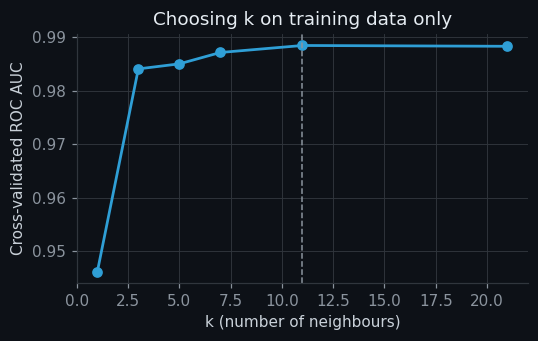

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}

for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, weights="distance")),
    ])
    scores = cross_val_score(candidate, Xc_train, yc_train, cv=cv, scoring="roc_auc")
    cv_scores[k] = scores.mean()
    print(f"k={k:2d}  cross-validated ROC AUC = {scores.mean():.3f}")

best_k = max(cv_scores, key=cv_scores.get)
print("selected k:", best_k)
pd.Series(cv_scores, name="cv_roc_auc").to_csv(RESULTS / "knn_cv_scores.csv", index_label="k")
summary["knn_cv_roc_auc"] = {str(k): round(float(v), 4) for k, v in cv_scores.items()}
summary["best_k"] = int(best_k)

plt.figure(figsize=(5, 3.2))
plt.plot(k_values, [cv_scores[k] for k in k_values], marker="o")
plt.axvline(best_k, linestyle="--", color=MUTED, linewidth=1)
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
save_plot("knn_choosing_k.png")

**Observations.** Cross-validated ROC AUC jumps from 0.946 at k=1 to 0.984 at k=3, then creeps up to 0.988 at k=11 and k=21. One neighbour copies every quirk of the training rows; from k=7 on the scores are level, as the handout says. The search picks k=11.

With `k` locked, both models are compared on the validation split.

In [4]:
models = {
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
    ]),
    "GaussianNB": Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianNB()),
    ]),
}

family_scores = {}
for name, model in models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_valid)
    prob_c = model.predict_proba(Xc_valid)[:, 1]
    family_scores[name] = {"accuracy": accuracy_score(yc_valid, pred),
                           "roc_auc": roc_auc_score(yc_valid, prob_c)}
    print(f"{name:10s} accuracy={family_scores[name]['accuracy']:.3f} "
          f"roc_auc={family_scores[name]['roc_auc']:.3f}")
summary["cancer_validation"] = pd.DataFrame(family_scores).round(4).to_dict()

KNN        accuracy=0.958 roc_auc=0.986
GaussianNB accuracy=0.944 roc_auc=0.992


**Observations.** On the validation tumours, KNN gets the higher accuracy (0.958 against 0.944) and naive Bayes the higher ROC AUC (0.992 against 0.986). As with Titanic in Lab 2, the two metrics disagree on the winner, and the accuracy gap is two tumours out of 143.

Two-feature boundaries on tumour radius and texture, with logistic regression as a reference.
Cyan is benign and orange is malignant, as in Lab 2.

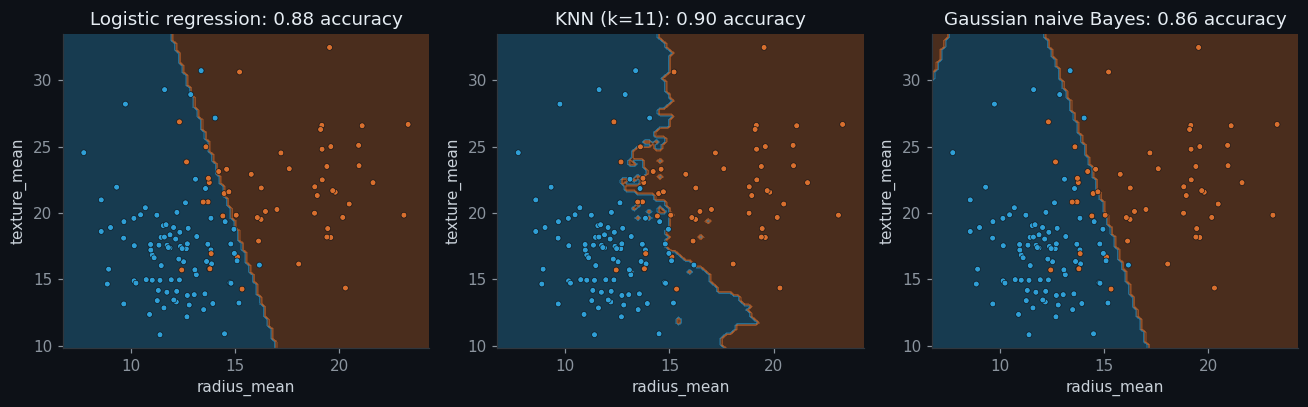

In [5]:
two = ["radius_mean", "texture_mean"]
boundary_accuracy = {}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, estimator) in zip(axes, [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    (f"KNN (k={best_k})", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
    ("Gaussian naive Bayes", GaussianNB()),
]):
    small = Pipeline([("scale", StandardScaler()), ("model", estimator)])
    small.fit(Xc_train[two], yc_train)
    DecisionBoundaryDisplay.from_estimator(small, Xc_valid[two], ax=ax, alpha=0.3,
                                           response_method="predict", cmap=CLASSES)
    ax.scatter(Xc_valid[two[0]], Xc_valid[two[1]], c=yc_valid, cmap=CLASSES,
               s=14, edgecolor="#0d1117", linewidth=0.4)
    boundary_accuracy[name] = accuracy_score(yc_valid, small.predict(Xc_valid[two]))
    ax.set_title(f"{name}: {boundary_accuracy[name]:.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")
    ax.grid(False)
plt.tight_layout()
save_plot("cancer_decision_boundaries.png")
summary["two_feature_accuracy"] = {k: round(float(v), 4) for k, v in boundary_accuracy.items()}

**Observations.** With only radius and texture, each model draws the boundary its assumptions allow: logistic regression a straight line, naive Bayes a curve (two Gaussians with different spreads meet on a curve), and KNN a ragged edge that follows local votes. KNN scores best on these two features (0.90 accuracy), then logistic regression (0.88) and naive Bayes (0.86). All three fall well short of the 30-feature models, so most of the signal sits in the other 28 columns.

## Part B: One readable decision tree, and what happens as it grows

Trees split on the order of values, so the numeric columns only need their gaps filled, not
scaling.

In [6]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]
X_t = titanic[features]
y_t = titanic["Survived"]

tree_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), t_num),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), t_cat),
])

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=12, random_state=42)),
])
tree.fit(Xt_train, yt_train)
tree_train_acc = accuracy_score(yt_train, tree.predict(Xt_train))
tree_valid_acc = accuracy_score(yt_valid, tree.predict(Xt_valid))
print("training accuracy:", round(tree_train_acc, 3))
print("validation accuracy:", round(tree_valid_acc, 3))
summary["tree_depth4"] = {"train_accuracy": round(tree_train_acc, 4),
                          "validation_accuracy": round(tree_valid_acc, 4)}

training accuracy: 0.843
validation accuracy: 0.767


Print and plot the tree: the split questions, the sample counts and the classes.

|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 48.09
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  48.09
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Age <= 53.00
|   |   |   |   |--- class: 0
|   |   |   |--- num__Age >  53.00
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- num__Fare <= 7.89
|   |   |   |--- cat__Embarked_S <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Embarked_S >  0.50
|   |

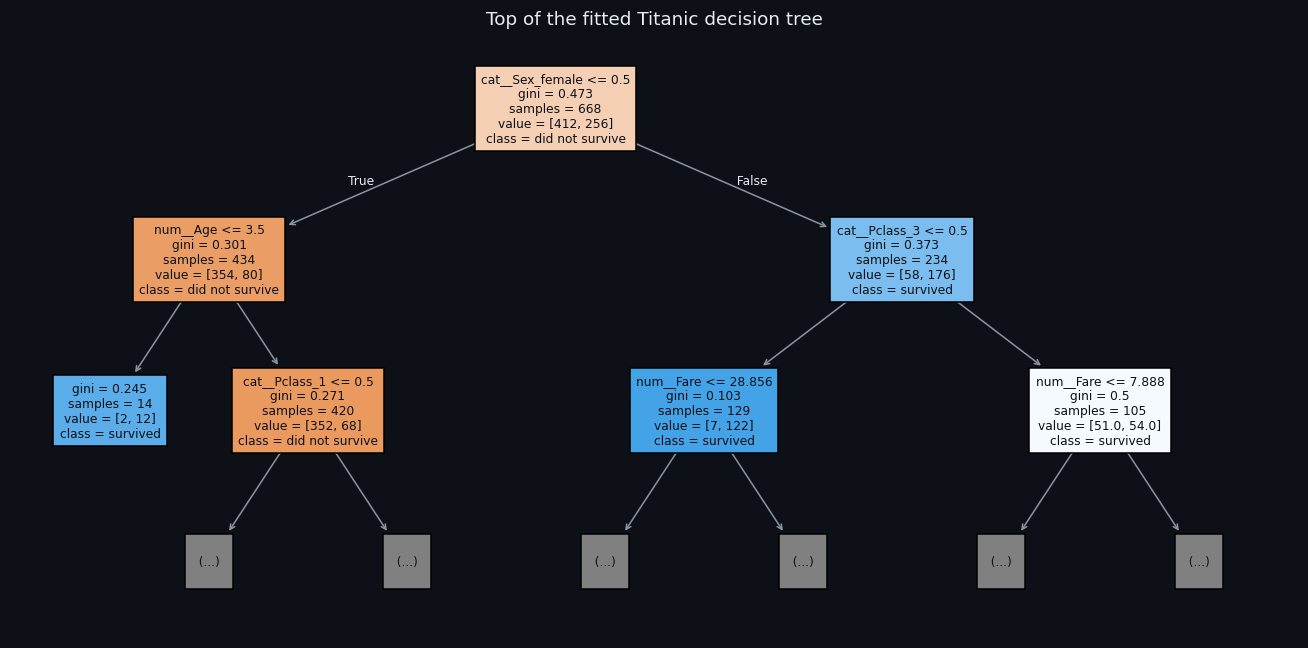

In [7]:
feature_names = list(tree.named_steps["preprocess"].get_feature_names_out())
print(export_text(tree.named_steps["tree"], feature_names=feature_names, max_depth=3))

plt.figure(figsize=(12, 6))
arrows = plot_tree(tree.named_steps["tree"], feature_names=feature_names,
                   class_names=["did not survive", "survived"], max_depth=2, filled=True,
                   fontsize=8)
for node in arrows:  # dark text on the light node boxes, muted arrows on the dark page
    if node.get_bbox_patch() is not None:
        node.set_color("#0d1117")
    if node.arrow_patch is not None:
        node.arrow_patch.set_color(MUTED)
plt.title("Top of the fitted Titanic decision tree")
plt.tight_layout()
save_plot("titanic_tree.png")

**Observations.** The depth-4 tree scores 0.843 on training rows and 0.767 on validation. The first question is sex. For men, the next split is age: boys of 3 or younger are predicted to survive, and every other branch for men ends in *did not survive*, whatever the class or fare. For women, the next split is ticket class: every branch for women outside third class ends in *survived*, while third-class women split on fare and age. That matches the handout: sex first, then age for men and class for women.

Fit each depth and compare training with validation accuracy.

max_depth,1,2,3,4,5,6,7,8,9,10,11,12
train_accuracy,0.793,0.808,0.832,0.852,0.868,0.882,0.892,0.913,0.927,0.939,0.948,0.954
validation_accuracy,0.767,0.758,0.785,0.776,0.767,0.771,0.767,0.740,0.749,0.740,0.740,0.731


best validation depth: 3


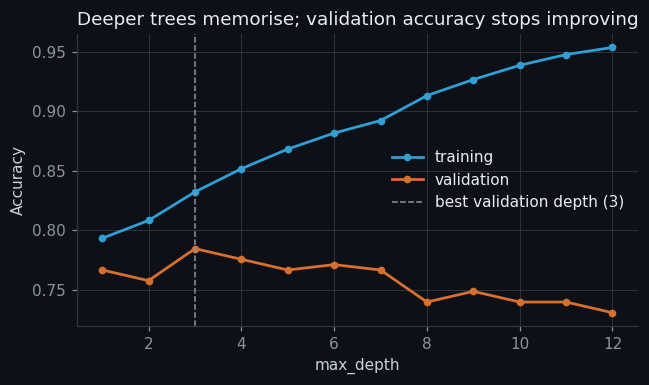

In [8]:
depths = list(range(1, 13))
train_acc, valid_acc = [], []
for depth in depths:
    t = Pipeline([
        ("preprocess", tree_preprocess),
        ("tree", DecisionTreeClassifier(max_depth=depth, random_state=42)),
    ]).fit(Xt_train, yt_train)
    train_acc.append(accuracy_score(yt_train, t.predict(Xt_train)))
    valid_acc.append(accuracy_score(yt_valid, t.predict(Xt_valid)))

depth_table = pd.DataFrame({"train_accuracy": train_acc, "validation_accuracy": valid_acc},
                           index=pd.Index(depths, name="max_depth"))
depth_table.to_csv(RESULTS / "titanic_tree_depth.csv")
display(depth_table.round(3).T)
best_depth = int(depth_table["validation_accuracy"].idxmax())
print("best validation depth:", best_depth)
summary["tree_depth_sweep"] = {"best_validation_depth": best_depth,
                               "validation_at_best": round(float(depth_table["validation_accuracy"].max()), 4),
                               "train_at_depth_12": round(float(train_acc[-1]), 4),
                               "validation_at_depth_12": round(float(valid_acc[-1]), 4)}

plt.figure(figsize=(6, 3.6))
plt.plot(depths, train_acc, marker="o", markersize=4, label="training")
plt.plot(depths, valid_acc, marker="o", markersize=4, label="validation")
plt.axvline(best_depth, linestyle="--", color=MUTED, linewidth=1, label=f"best validation depth ({best_depth})")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Deeper trees memorise; validation accuracy stops improving")
plt.legend()
plt.tight_layout()
save_plot("titanic_tree_depth.png")

**Observations.** Training accuracy climbs with every extra level, from 0.793 at depth 1 to 0.954 at depth 12. Validation peaks at depth 3 (0.785) and drifts down to 0.731 at depth 12: past depth 3 the extra splits fit noise in the training rows, which is where overfitting starts on this split. The differences are small, though. One validation passenger is worth 0.0045 accuracy, so the peak at depth 3 is four passengers above depth 1.

## Part C: Random forest versus gradient boosting

Model log(1 + price) from Ames Housing's mixed-type features, and compare the two ensembles
on the same three folds.

random_forest      CV log-RMSE = 0.1382 +/- 0.0118


gradient_boosting  CV log-RMSE = 0.1273 +/- 0.0141
rows: 2930  input columns: 79


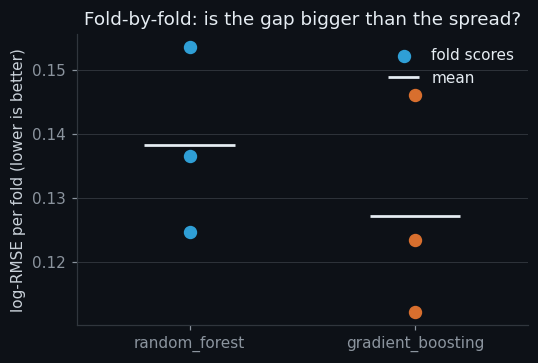

In [9]:
ames = pd.read_csv(DATA / "ames_housing_dataset.csv")
X_a = ames.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")  # identifiers out
y_a = np.log1p(ames["SalePrice"])

ames_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), X_a.select_dtypes(include="number").columns),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), X_a.select_dtypes(exclude="number").columns),
])
ensembles = {
    "random_forest": RandomForestRegressor(
        n_estimators=150, max_features=0.8, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=3, loss="huber", random_state=42
    ),
}

cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmse = {}
for name, estimator in ensembles.items():
    pipe = Pipeline([("preprocess", ames_preprocess), ("model", estimator)])
    neg_mse = cross_val_score(pipe, X_a, y_a, cv=cv3, scoring="neg_mean_squared_error")
    cv_rmse[name] = np.sqrt(-neg_mse)
    print(f"{name:18s} CV log-RMSE = {cv_rmse[name].mean():.4f} +/- {cv_rmse[name].std():.4f}")
print("rows:", X_a.shape[0], " input columns:", X_a.shape[1])
pd.DataFrame(cv_rmse, index=pd.Index([1, 2, 3], name="fold")).to_csv(RESULTS / "ames_cv_rmse.csv")
summary["ames_cv_log_rmse"] = {name: {"folds": [round(float(v), 4) for v in values],
                                      "mean": round(float(values.mean()), 4),
                                      "std": round(float(values.std()), 4)}
                               for name, values in cv_rmse.items()}

plt.figure(figsize=(5, 3.4))
for i, (name, values) in enumerate(cv_rmse.items()):
    plt.scatter([i] * len(values), values, s=60, label="fold scores" if i == 0 else None)
    plt.hlines(values.mean(), i - 0.2, i + 0.2, color=INK, label="mean" if i == 0 else None)
plt.xticks(range(len(cv_rmse)), list(cv_rmse))
plt.xlim(-0.5, len(cv_rmse) - 0.5)
plt.ylabel("log-RMSE per fold (lower is better)")
plt.title("Fold-by-fold: is the gap bigger than the spread?")
plt.legend()
plt.grid(axis="x", visible=False)
plt.tight_layout()
save_plot("ames_cv_folds.png")

**Observations.** Gradient boosting reaches the lower log-RMSE (0.127 against 0.138) and wins all three folds, by 0.007 to 0.013. The folds themselves swing more than that: the forest goes from 0.125 to 0.154 depending on which houses land in the held-out fold. So boosting's gain is consistent but small, about one fold standard deviation, or roughly 1% in typical price error. Whether that pays for boosting's slower, more sensitive tuning is a judgement call, as the handout says.

Repeat on eleven wine measurements, then shuffle each validation column to measure how much
the fitted forest relies on it.

random_forest      MAE = 0.432  RMSE = 0.565


gradient_boosting  MAE = 0.476  RMSE = 0.597


quality counts in validation: {3: 1, 4: 13, 5: 164, 6: 169, 7: 48, 8: 5}
boosting predicts [5.34] for the wine rated 3 and [6.9  6.58 6.5  6.31 6.93] for the wines rated 8
boosting predictions between 5 and 7: 94%


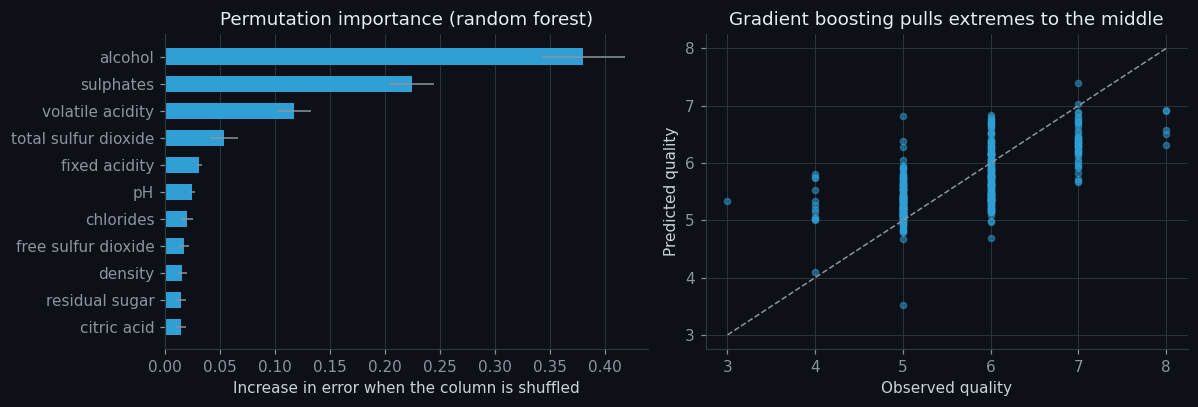

In [10]:
wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")
X_w = wine.drop(columns="quality")
y_w = wine["quality"]
Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(X_w, y_w, test_size=0.25, random_state=42)

wine_models = {
    "random_forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                           random_state=42, n_jobs=-1),
    "gradient_boosting": GradientBoostingRegressor(random_state=42),
}
wine_pred = {}
wine_scores = {}
for name, model in wine_models.items():
    model.fit(Xw_train, yw_train)
    wine_pred[name] = model.predict(Xw_valid)
    wine_scores[name] = {"MAE": mean_absolute_error(yw_valid, wine_pred[name]),
                         "RMSE": np.sqrt(mean_squared_error(yw_valid, wine_pred[name]))}
    print(f"{name:18s} MAE = {wine_scores[name]['MAE']:.3f}  RMSE = {wine_scores[name]['RMSE']:.3f}")
pd.DataFrame(wine_scores).T.to_csv(RESULTS / "wine_metrics.csv", index_label="model")
summary["wine"] = pd.DataFrame(wine_scores).round(4).to_dict()

importance = permutation_importance(
    wine_models["random_forest"], Xw_valid, yw_valid, n_repeats=10, random_state=42, n_jobs=-1
)
ranked = pd.Series(importance.importances_mean, index=X_w.columns).sort_values()
spread = importance.importances_std[np.argsort(importance.importances_mean)]
ranked.to_csv(RESULTS / "wine_importance.csv", index_label="feature", header=["mean_importance"])
summary["wine_top_features"] = ranked.sort_values(ascending=False).head(3).round(4).to_dict()
print("quality counts in validation:", yw_valid.value_counts().sort_index().to_dict())
gb_pred, observed = wine_pred["gradient_boosting"], yw_valid.to_numpy()
print("boosting predicts", gb_pred[observed == 3].round(2), "for the wine rated 3 and",
      gb_pred[observed == 8].round(2), "for the wines rated 8")
print(f"boosting predictions between 5 and 7: {((gb_pred >= 5) & (gb_pred <= 7)).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(ranked.index, ranked.values, xerr=spread, height=0.6, color=CYAN,
             error_kw={"ecolor": MUTED, "elinewidth": 1})
axes[0].set_xlabel("Increase in error when the column is shuffled")
axes[0].set_title("Permutation importance (random forest)")
axes[0].grid(axis="y", visible=False)
axes[1].scatter(yw_valid, wine_pred["gradient_boosting"], alpha=0.5, s=16)
axes[1].plot([3, 8], [3, 8], linestyle="--", color=MUTED, linewidth=1)
axes[1].set_xlabel("Observed quality")
axes[1].set_ylabel("Predicted quality")
axes[1].set_title("Gradient boosting pulls extremes to the middle")
plt.tight_layout()
save_plot("wine_importance.png")

**Observations.** Here the forest wins: MAE 0.432 against 0.476 and RMSE 0.565 against 0.597, the reverse of Ames. Shuffling alcohol hurts the forest most, then sulphates and volatile acidity; the other eight columns matter far less. (The importances are drops in R², the forest's default score.) The scatter shows the squeeze: 94% of boosting's predictions land between 5 and 7, the single wine rated 3 comes out at 5.34, and the five wines rated 8 at 6.31 to 6.93. With 333 of the 400 validation wines rated 5 or 6, the model learns to stay near the middle.

## Part D: Support vector machines, two dials and a kernel

Scaling sits inside the pipeline, so each training fold fits its own scaler. `C` sets the
penalty for margin violations, the kernel sets the shape of the boundary, and the RBF `gamma`
sets how local each training point's influence is.

As in Lab 2, this split uses the same seed and size as Part A, so the test rows here are the
tumours Part A used for validation. The grid search never sees them, but they are not
completely fresh: Part A already scored two models on them.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)

svm_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])
search = GridSearchCV(
    svm_pipe,
    param_grid={
        "model__kernel": ["linear", "rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
search.fit(X_train, y_train)

score = search.decision_function(X_test)
pred = search.predict(X_test)
print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("test accuracy:", round(accuracy_score(y_test, pred), 3))
print("test ROC AUC:", round(roc_auc_score(y_test, score), 3))
summary["svm"] = {"best_parameters": {k: (v if isinstance(v, str) else float(v))
                                      for k, v in search.best_params_.items()},
                  "cv_roc_auc": round(float(search.best_score_), 4),
                  "test_accuracy": round(float(accuracy_score(y_test, pred)), 4),
                  "test_roc_auc": round(float(roc_auc_score(y_test, score)), 4)}

best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
cross-validated ROC AUC: 0.995
test accuracy: 0.979
test ROC AUC: 0.997


**Observations.** The search picks an RBF kernel with C=10 and gamma=0.01, at a cross-validated ROC AUC of 0.995. On the test tumours it reaches 0.979 accuracy, three mistakes out of 143, and a test ROC AUC of 0.997.

Cross-validated AUC for each (C, gamma) pair, then two-feature boundaries for a linear and an
RBF kernel.

gamma,0.01,0.1,scale
param_model__C,,,
0.1,0.9852,0.9782,0.9828
1.0,0.9925,0.9884,0.9942
10.0,0.9954,0.9817,0.9937
100.0,0.9945,0.9815,0.9885


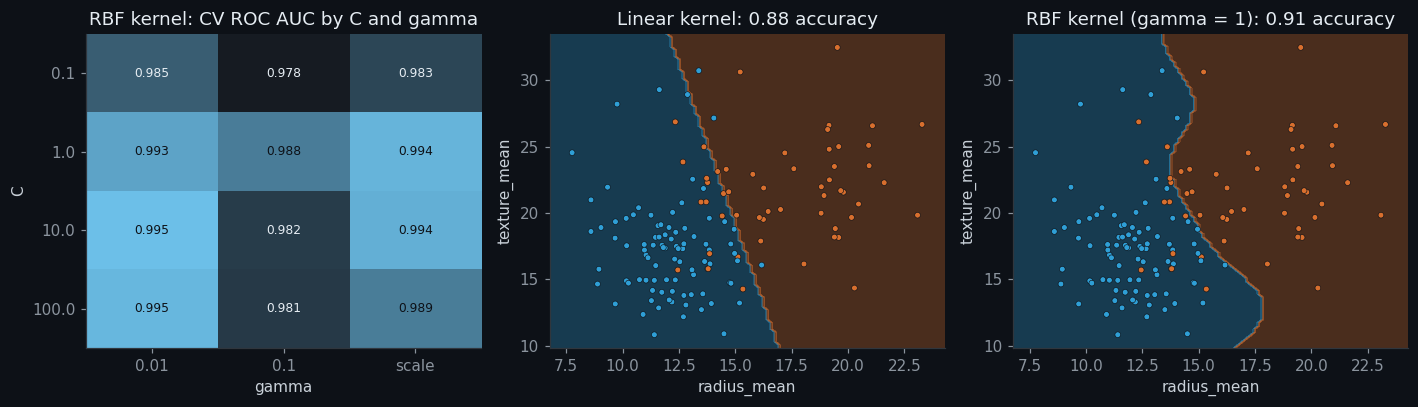

In [12]:
results = pd.DataFrame(search.cv_results_)
results[["param_model__kernel", "param_model__C", "param_model__gamma", "mean_test_score",
         "std_test_score", "rank_test_score"]].to_csv(RESULTS / "svm_cv_results.csv", index=False)
rbf = results[results["param_model__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_model__gamma"].astype(str)
grid = rbf.pivot(index="param_model__C", columns="gamma", values="mean_test_score")
display(grid.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
im = axes[0].imshow(grid.values, cmap=HEAT, aspect="auto")
axes[0].set_xticks(range(len(grid.columns)), grid.columns)
axes[0].set_yticks(range(len(grid.index)), grid.index)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")
axes[0].grid(False)
middle = (grid.values.min() + grid.values.max()) / 2
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[0].text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center",
                     color="#0d1117" if grid.values[i, j] > middle else INK, fontsize=8)
axes[0].set_title("RBF kernel: CV ROC AUC by C and gamma")
for ax, (title, estimator) in zip(axes[1:], [
    ("Linear kernel", SVC(kernel="linear", C=1)),
    ("RBF kernel (gamma = 1)", SVC(kernel="rbf", C=1, gamma=1.0)),
]):
    small = Pipeline([("scale", StandardScaler()), ("model", estimator)]).fit(X_train[two], y_train)
    DecisionBoundaryDisplay.from_estimator(small, X_test[two], ax=ax, alpha=0.3,
                                           response_method="predict", cmap=CLASSES)
    ax.scatter(X_test[two[0]], X_test[two[1]], c=y_test, cmap=CLASSES,
               s=14, edgecolor="#0d1117", linewidth=0.4)
    ax.set_title(f"{title}: {accuracy_score(y_test, small.predict(X_test[two])):.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")
    ax.grid(False)
plt.tight_layout()
save_plot("svm_grid_boundaries.png")

**Observations.** Every RBF setting scores between 0.978 and 0.995, and gamma=0.1 is the weakest column at every C: with that much locality the boundary starts chasing individual tumours. On radius and texture alone, the RBF kernel with gamma=1 bends around the overlap and scores 0.91 against the linear kernel's 0.88. That gain belongs to the two-feature slice, though. With all 30 scaled features the classes are close to linearly separable, and the *Try it yourself* comparison below shows the linear kernel matching RBF on the test set.

Save, reload, and check that the reloaded model reproduces the test predictions before
sharing the file.

In [13]:
model_path = MODELS / "breast_cancer_svm.joblib"
joblib.dump(search.best_estimator_, model_path)
loaded = joblib.load(model_path)
same = np.array_equal(loaded.predict(X_test), pred)
print("file size (KB):", round(model_path.stat().st_size / 1024, 1))
print("reloaded model reproduces the test predictions:", same)
assert same
summary["svm_reload_matches"] = bool(same)

file size (KB): 16.5
reloaded model reproduces the test predictions: True


## Try it yourself

### An unpruned tree

Grow the Titanic tree with `max_depth=None` and `min_samples_leaf=1`, and compare its
training and validation accuracy with the depth-4 tree.

In [14]:
full_tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, random_state=42)),
]).fit(Xt_train, yt_train)

tree_compare = pd.DataFrame({
    "depth-4 tree": {"depth": tree.named_steps["tree"].get_depth(),
                     "leaves": tree.named_steps["tree"].get_n_leaves(),
                     "training accuracy": tree_train_acc,
                     "validation accuracy": tree_valid_acc},
    "unpruned tree": {"depth": full_tree.named_steps["tree"].get_depth(),
                      "leaves": full_tree.named_steps["tree"].get_n_leaves(),
                      "training accuracy": accuracy_score(yt_train, full_tree.predict(Xt_train)),
                      "validation accuracy": accuracy_score(yt_valid, full_tree.predict(Xt_valid))},
}).T
display(tree_compare.round(3))
summary["tree_unpruned"] = tree_compare.loc["unpruned tree"].round(4).to_dict()

,depth,leaves,training accuracy,validation accuracy
depth-4 tree,4.0,13.0,0.843,0.767
unpruned tree,21.0,146.0,0.978,0.722


**Observations.** Unpruned, the tree grows to depth 21 with 146 leaves. Training accuracy jumps to 0.978, nearly memorising the 668 training passengers, while validation accuracy falls to 0.722, below the depth-4 tree's 0.767. The extra 133 leaves fit noise: the overfitting from the depth sweep, taken all the way.

### A linear-only SVM search

Refit the search with only the linear kernel and compare its test ROC AUC with the RBF result.
The RBF side gets the same treatment, a search over RBF settings only, so both kernels are
compared at their own best settings.

In [15]:
kernel_searches = {}
for kernel, grid_ in {
    "linear": {"model__kernel": ["linear"], "model__C": [0.1, 1, 10, 100]},
    "rbf": {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", 0.01, 0.1]},
}.items():
    kernel_searches[kernel] = GridSearchCV(
        svm_pipe, param_grid=grid_, cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring="roc_auc", n_jobs=-1,
    ).fit(X_train, y_train)

kernel_table = pd.DataFrame({
    kernel: {"best parameters": {k.replace("model__", ""): v for k, v in s.best_params_.items()},
             "cross-validated ROC AUC": round(s.best_score_, 4),
             "test ROC AUC": round(roc_auc_score(y_test, s.decision_function(X_test)), 4),
             "test accuracy": round(accuracy_score(y_test, s.predict(X_test)), 4)}
    for kernel, s in kernel_searches.items()
}).T
display(kernel_table)
summary["svm_by_kernel"] = {kernel: {"cv_roc_auc": float(row["cross-validated ROC AUC"]),
                                     "test_roc_auc": float(row["test ROC AUC"]),
                                     "test_accuracy": float(row["test accuracy"])}
                            for kernel, row in kernel_table.iterrows()}

(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8");

,best parameters,cross-validated ROC AUC,test ROC AUC,test accuracy
linear,"{'C': 0.1, 'kernel': 'linear'}",0.9932,0.9971,0.979
rbf,"{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.9954,0.9969,0.979


**Observations.** At their own best settings the two kernels tie on the test set: linear (C=0.1) gets a test ROC AUC of 0.9971 and RBF (C=10, gamma=0.01) 0.9969, with the same 0.979 accuracy. RBF's small cross-validation edge (0.9954 against 0.9932) does not carry over to the test rows. When the simpler model does as well, I would keep the linear kernel: it has one setting fewer to tune (no gamma), and its weights can be read off directly.

## Verification checklist

- **Lab 2's fixed validation workflow.** The classifiers use Lab 2's stratified 25% split with `random_state=42`; the regressors use a 25% split (wine) or three shuffled folds (Ames) with the same seed. Every preprocessing step sits inside a pipeline.
- **Validation, not training fit, picks k and the depth.** Cross-validation on the training rows picks k=11 (Part A). The depth sweep puts the validation peak at depth 3, with training accuracy still rising past it, which marks the overfitting point (Part B).
- **Forest against boosting, judged against the folds.** Boosting's 0.011 gain on Ames is about one fold standard deviation, though it wins all three folds (Part C).
- **SVM tuned on scaled inputs.** `C`, `gamma` and the kernel come from five-fold cross-validation, with the scaler refitted inside each fold (Part D).
- **The saved model reloads.** `models/breast_cancer_svm.joblib` reproduces the test predictions exactly, and the notebook asserts it (end of Part D).

## Check your understanding

**1. What is the geometric meaning of a larger separating margin in an SVM?**

The margin is the empty band between the decision boundary and the closest training points
of each class, the support vectors. Its width is 2 / ||w||, so maximizing the margin means
keeping the weights small. A wider margin puts the boundary farther from both classes: a
point has to move further before its prediction flips, and the model has less room to bend
around individual training points, which usually generalizes better.

**2. How do C and, for an RBF kernel, gamma change the flexibility of the fitted decision boundary?**

`C` is the price of each margin violation. A large `C` tolerates few violations, so the
margin narrows and the boundary bends to classify more training points correctly (more
flexible, more risk of overfitting). A small `C` accepts violations in exchange for a wider
margin and a smoother boundary. `gamma` sets how far one training point's influence reaches
in the RBF kernel. A large `gamma` makes each support vector matter only very close to
itself, so the boundary can wrap around small clusters; a small `gamma` spreads the
influence wide, and the boundary flattens towards a linear one.

**3. Why should scaling and SVM hyperparameter selection both happen inside the validation procedure?**

SVMs work on distances and dot products, so a feature measured in thousands (tumour area)
would swamp one measured in fractions (smoothness) without scaling. If the scaler learns its
means and standard deviations from all rows before cross-validation, every validation fold
has already leaked into the training data. The best `C` and `gamma` also depend on that
scale, so they have to be chosen on folds scaled the same way the model will see new data.
And if the test set helps pick `C` or `gamma`, its score stops being an honest estimate.
A `Pipeline` inside `GridSearchCV` keeps all three in order: each fold fits its own scaler,
the search only ever sees training folds, and the test set is scored once at the end.